In [1]:
import chipwhisperer as cw
import numpy as np
import struct
import matplotlib.pyplot as plt
import time
scope = cw.scope()
target = cw.target(scope)
scope.default_setup()

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      
    "mathtext.default": "regular", 
    "figure.figsize": (8, 5),
    "font.size": 11,
})

(ChipWhisperer Other WARNING|File __init__.py:69) ChipWhisperer update available! See https://chipwhisperer.readthedocs.io/en/latest/installing.html for updating instructions


make: Entering directory '/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/32-bit/firmware/timing_attack_ARM'
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CW308_STM32F3 
.
Compiling:
-en     timing_attack_arm.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal_lowlevel.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_sysmem.c ...
-e Done!
.
Assembling: .././hal//stm32f3/stm32f3_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -x assembler-with-cpp 

ReLU capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for ReLU! Plotting results...


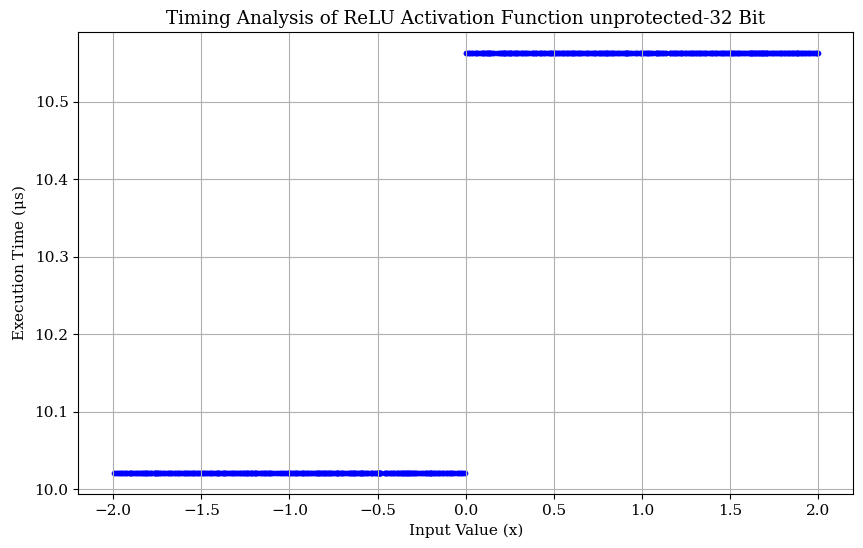

Capturing sigmoid unprotected...


sigmoid capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for sigmoid! Plotting results...


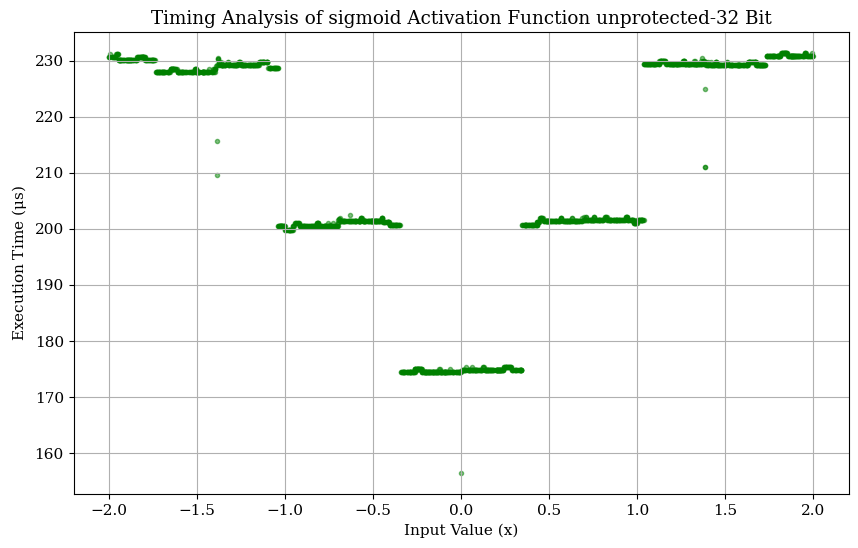

Capturing tanh unprotected...


tanh capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for tanh! Plotting results...


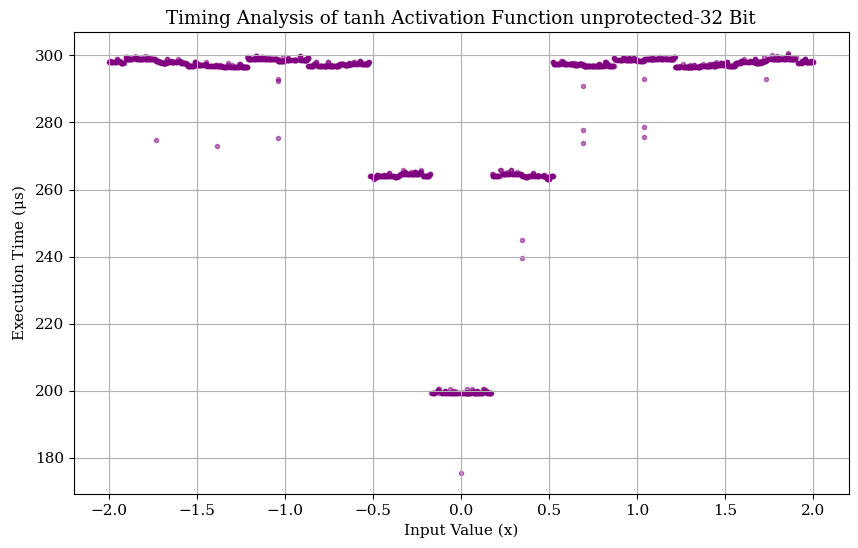

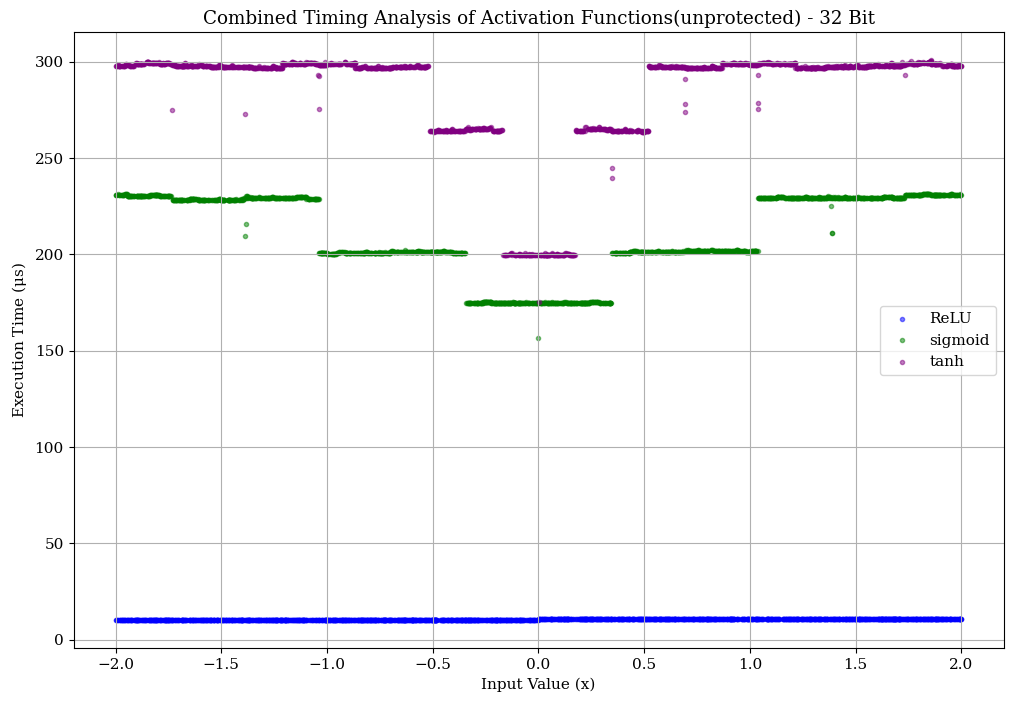


--- Execution Time Statistics (Microseconds) ---
Function   | Fastest (C) | Slowest (C) | Average   
-----------------------------------------------
ReLU       | 10.02      | 10.56      | 10.29     
sigmoid    | 174.71     | 229.46     | 209.81    
tanh       | 199.44     | 297.85     | 284.75    
-----------------------------------------------


--- Countermeasure Parameters ---
Cluster Fastest: 10.02 us
Cluster Slowest: 297.85 us
Absolute Fastest: 10.02 us
Absolute Slowest: 300.63 us
Absolute Delta t/Mean (mu): 287.83 us
Max Local Difference/StdDev (sigma): 125.26 us
------------------------------------------


In [ ]:
"""
Timing Attack Analysis Script for 32-bit ARM Cortex-M4 (STM32F3)
UNPROTECTED
"""

import struct
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans
from tqdm.notebook import tqdm
import os


# --- Target Setup & Firmware Compilation ---

PLATFORM = 'CW308_STM32F3'
FW_PATH = "../firmware/timing_attack_ARM/"
!make -C "{FW_PATH}" PLATFORM={PLATFORM} CRYPTO_TARGET=NONE
hex_path = os.path.join(FW_PATH, f"timing_attack_arm-{PLATFORM}.hex")
cw.program_target(scope, cw.programmers.STM32FProgrammer, hex_path)


def capture_and_plot(activation_name, choice_val=None, num_traces=2000, suffix="", color="red"):
    """
    Captures execution times of an activation function using random inputs and plots them.
    """
    
    # Generate random inputs
    inputs = np.random.uniform(-2, 2, num_traces)
    execution_times_us = [] 

    print(f"Capturing {activation_name}{suffix}...")

    # Get ADC sampling frequency to convert cycles to microseconds
    adc_freq = scope.clock.adc_freq 

    for x in tqdm(inputs, desc=f"{activation_name} capture"):
        # Payload: 1-byte function choice + 4-byte float input (little endian)
        pt = bytearray([choice_val]) + bytearray(struct.pack('<f', x))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        
        ret = scope.capture()
        if ret:
            print("Timeout error!")
            break
            
        # Get execution time in cycles and convert to microseconds
        cycles = scope.adc.trig_count
        time_us = (cycles / adc_freq) * 1e6 
        execution_times_us.append(time_us)
        
        # Read 4 bytes to clear the serial buffer
        target.simpleserial_read('r', 4)

    print(f"Capture complete for {activation_name}! Plotting results...")

    plt.figure(figsize=(10, 6))
    plt.scatter(inputs, execution_times_us, marker='.', color=color, alpha=0.5)
    plt.title(f"Timing Analysis of {activation_name} Activation Function{suffix}-32 Bit")
    plt.xlabel("Input Value (x)")
    plt.ylabel(r"Execution Time ($\mu s$)")
    plt.grid(True)
    plt.savefig(f"{activation_name}-{suffix}-ARM.pdf", bbox_inches='tight')
    plt.show()
    
    return inputs, execution_times_us


def print_cluster_stats(name, execution_times_us, num_clusters):
    """
    Finds discrete timing groups (branches) using K-Means clustering.
    """
    # Reshape data for K-Means
    data = np.array(execution_times_us, dtype=float).reshape(-1, 1)
    
    # Run K-Means to find centroids (mean times)
    centroids, _ = kmeans(data, num_clusters)
    
    fastest_cluster_mean = np.min(centroids)
    slowest_cluster_mean = np.max(centroids)
    overall_avg = np.mean(data)
    
    print(f"{name:<10} | {fastest_cluster_mean:<10.2f} | {slowest_cluster_mean:<10.2f} | {overall_avg:<10.2f}")
    return fastest_cluster_mean, slowest_cluster_mean, overall_avg


# --- Data Collection ---
relu_in, relu_out = capture_and_plot("ReLU", 0, suffix=" unprotected", color="blue")
sig_in, sig_out = capture_and_plot("sigmoid", 1, suffix=" unprotected", color="green")
tanh_in, tanh_out = capture_and_plot("tanh", 2, suffix=" unprotected", color="purple")


# --- Combined Visualization ---
plt.figure(figsize=(12, 8))

plt.scatter(relu_in, relu_out, marker='.', color="blue", alpha=0.5, label="ReLU")
plt.scatter(sig_in, sig_out, marker='.', color="green", alpha=0.5, label="sigmoid")
plt.scatter(tanh_in, tanh_out, marker='.', color="purple", alpha=0.5, label="tanh")

plt.title("Combined Timing Analysis of Activation Functions(unprotected) - 32 Bit")
plt.xlabel("Input Value (x)")
plt.ylabel(r"Execution Time ($\mu s$)")
plt.legend()
plt.grid(True)
plt.savefig('combined_timing_ARM.pdf', bbox_inches='tight')
plt.show()


# --- Statistical Analysis ---
print("\n--- Execution Time Statistics (Microseconds) ---")
print(f"{'Function':<10} | {'Fastest (C)':<10} | {'Slowest (C)':<10} | {'Average':<10}")
print("-" * 47)

# Calculate clusters based on expected execution branches
f_relu, s_relu, _ = print_cluster_stats("ReLU", relu_out, num_clusters=2)
f_sig, s_sig, _ = print_cluster_stats("sigmoid", sig_out, num_clusters=3)
f_tanh, s_tanh, _ = print_cluster_stats("tanh", tanh_out, num_clusters=3)
print("-" * 47 + "\n")


# --- Countermeasure Parameter Calculation ---

# Get global cluster bounds
cluster_fastest = min(f_relu, f_sig, f_tanh)
cluster_slowest = max(s_relu, s_sig, s_tanh)

# Get absolute min/max execution times
absolute_fastest = min(np.min(relu_out), np.min(sig_out), np.min(tanh_out))
absolute_slowest = max(np.max(relu_out), np.max(sig_out), np.max(tanh_out))

# Delta T: padding needed to make fastest executions match the slowest (represents 'mu' for delay)
mean_delay_needed = abs(cluster_slowest - cluster_fastest)

# Max internal variance among functions (represents 'sigma' for delay)
relu_diff = np.max(relu_out) - np.min(relu_out)
sig_diff = np.max(sig_out) - np.min(sig_out)
tanh_diff = np.max(tanh_out) - np.min(tanh_out)
stddev_us = max(relu_diff, sig_diff, tanh_diff)

print("\n--- Countermeasure Parameters ---")
print(f"Cluster Fastest: {cluster_fastest:.2f} us")
print(f"Cluster Slowest: {cluster_slowest:.2f} us")
print(f"Absolute Fastest: {absolute_fastest:.2f} us")
print(f"Absolute Slowest: {absolute_slowest:.2f} us")
print(f"Absolute Delta t/Mean (mu): {mean_delay_needed:.2f} us")
print(f"Max Local Difference/StdDev (sigma): {stddev_us:.2f} us")
print("-" * 42)


In [ ]:
"""
FIXED VS RANDOM TRACE COLLECTION - PROTECTED
"""
import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm

def collect_traces(activation_name, choice_val, N=5000):
    fixed_input = np.random.uniform(-2, 2)
    random_inputs = np.random.uniform(-2, 2, N)

    fixed_times = []
    random_times = []

    print(f"Collecting {N} FIXED traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} FIXED"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', fixed_input))
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        fixed_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    print(f"Collecting {N} RANDOM traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} RANDOM"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', random_inputs[i]))
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        random_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    return fixed_times, random_times

# COLLECT ALL DATA HERE
relu_fixed, relu_random = collect_traces("ReLU", 0)
sig_fixed, sig_random = collect_traces("sigmoid", 1)
tanh_fixed, tanh_random = collect_traces("tanh", 2)


ReLU FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

ReLU RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for ReLU...


/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/chipwhisperer/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


sigmoid FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for sigmoid...


tanh FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for tanh...


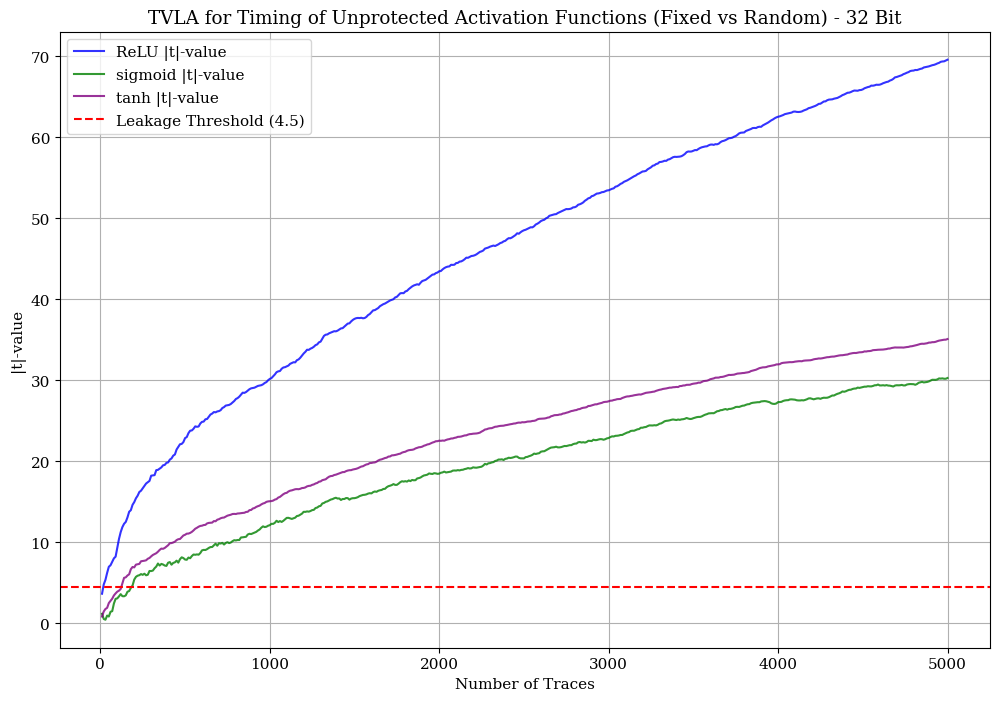

In [ ]:
"""
TVLA TEST
"""

def calc_tvla_evolution(fixed_times, random_times):
    t_values = []
    traces_axis = range(5, len(fixed_times) + 1, 5)
    for i in traces_axis:
        t_stat, _ = ttest_ind(fixed_times[:i], random_times[:i], equal_var=False)
        t_values.append(abs(t_stat))
    return traces_axis, t_values

traces_axis, relu_t = calc_tvla_evolution(relu_fixed, relu_random)
_, sig_t = calc_tvla_evolution(sig_fixed, sig_random)
_, tanh_t = calc_tvla_evolution(tanh_fixed, tanh_random)


# Evolution of |t|-value overlayed
plt.figure(figsize=(12, 8))

plt.plot(traces_axis, relu_t, color='blue', label='ReLU |t|-value', alpha=0.8)
plt.plot(traces_axis, sig_t, color='green', label='sigmoid |t|-value', alpha=0.8)
plt.plot(traces_axis, tanh_t, color='purple', label='tanh |t|-value', alpha=0.8)

# Add the classical ±4.5 threshold line (since it's absolute |t|, just 4.5)
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Timing of protected Activation Functions (Fixed vs Random) - 32 Bit")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig(f"TVLA for Timing of protected Activation Functions (Fixed vs Random)_ARM.pdf", bbox_inches='tight')
plt.show()


In [4]:
"""
Timing Attack Analysis Script for 32-bit ARM Cortex-M4 (STM32F3)
PROTECTED
"""

import struct
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans
from tqdm.notebook import tqdm
import os

# --- Target Setup & Firmware Compilation ---

PLATFORM = 'CW308_STM32F3'
FW_PATH = "../firmware/timing_attack_ARM/"

!make -C "{FW_PATH}" PLATFORM={PLATFORM} CRYPTO_TARGET=NONE
hex_path = os.path.join(FW_PATH, f"timing_attack_arm-{PLATFORM}.hex")
cw.program_target(scope, cw.programmers.STM32FProgrammer, hex_path)


def capture_and_plot(activation_name, choice_val=None, num_traces=1000, suffix="", color="red"):
    """
    Captures execution times of an activation function using random inputs and plots them.
    """

    # Generate random inputs
    inputs = np.random.uniform(-2, 2, num_traces)
    execution_times_us = [] 

    print(f"Capturing {activation_name}{suffix}...")

    # Get ADC sampling frequency to convert cycles to microseconds
    adc_freq = scope.clock.adc_freq 

    for x in tqdm(inputs, desc=f"{activation_name} capture"):
        # Payload: 1-byte function choice + 4-byte float input (little endian)
        pt = bytearray([choice_val]) + bytearray(struct.pack('<f', x))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        
        ret = scope.capture()
        if ret:
            print("Timeout error!")
            break
            
        # Get execution time in cycles and convert to microseconds
        cycles = scope.adc.trig_count
        time_us = (cycles / adc_freq) * 1e6 
        execution_times_us.append(time_us)
        
        # Read 4 bytes to clear the serial buffer
        target.simpleserial_read('r', 4)

    print(f"Capture complete for {activation_name}! Plotting results...")

    plt.figure(figsize=(10, 6))
    plt.scatter(inputs, execution_times_us, marker='.', color=color, alpha=0.5)
    plt.title(f"Timing Analysis of {activation_name} Activation Function{suffix}")
    plt.xlabel("Input Value (x)")
    plt.ylabel(r"Execution Time ($\mu s$)")
    plt.grid(True)
    plt.savefig(f"{activation_name}-{suffix}-ARM.pdf", bbox_inches='tight')
    plt.show()
    
    return inputs, execution_times_us


# --- Data Collection ---
relu_in, relu_out = capture_and_plot("ReLU", 0, suffix=" protected", color="blue")
sig_in, sig_out = capture_and_plot("sigmoid", 1, suffix=" protected", color="green")
tanh_in, tanh_out = capture_and_plot("tanh", 2, suffix=" protected", color="purple")


# --- Combined Visualization ---
plt.figure(figsize=(12, 8))

plt.scatter(relu_in, relu_out, marker='.', color="blue", alpha=0.5, label="ReLU")
plt.scatter(sig_in, sig_out, marker='.', color="green", alpha=0.5, label="sigmoid")
plt.scatter(tanh_in, tanh_out, marker='.', color="purple", alpha=0.5, label="tanh")

plt.title("Combined Timing Analysis of Activation Functions(protected) - 32 Bit")
plt.xlabel("Input Value (x)")
plt.ylabel(r"Execution Time ($\mu s$)")
plt.legend()
plt.grid(True)
plt.savefig('combined_timing_ARM(protected).pdf', bbox_inches='tight')
plt.show()


# --- Overlay Histogram Visualization ---
plt.figure(figsize=(10, 6))

plt.hist(relu_out, bins=60, color='blue', alpha=0.8, label='ReLU')
plt.hist(sig_out, bins=60, color='red', alpha=0.8, label="sigmoid")
plt.hist(tanh_out, bins=60, color='green', alpha=0.8, label="tanh")

plt.title("Combined Timing distribution of Activation Functions(protected) - 32 Bit")
plt.xlabel(r'Execution Time ($\mu s$)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.savefig('histogram(protected)_ARM.pdf', bbox_inches='tight')
plt.show()


make: Entering directory '/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/32-bit/firmware/timing_attack_ARM'
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CW308_STM32F3 
.
Compiling:
-en     timing_attack_arm.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal_lowlevel.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_sysmem.c ...
-e Done!
.
Assembling: .././hal//stm32f3/stm32f3_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -x assembler-with-cpp 

ReLU capture:   0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [50]:
"""
FIXED VS RANDOM TRACE COLLECTION - PROTECTED
"""
import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm

def collect_traces(activation_name, choice_val, N=5000):
    fixed_input = np.random.uniform(-2, 2)
    random_inputs = np.random.uniform(-2, 2, N)

    fixed_times = []
    random_times = []

    print(f"Collecting {N} FIXED traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} FIXED"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', fixed_input))
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        fixed_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    print(f"Collecting {N} RANDOM traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} RANDOM"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', random_inputs[i]))
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        random_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    return fixed_times, random_times

# COLLECT ALL DATA HERE
relu_fixed, relu_random = collect_traces("ReLU", 0)
sig_fixed, sig_random = collect_traces("sigmoid", 1)
tanh_fixed, tanh_random = collect_traces("tanh", 2)


ReLU FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

ReLU RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

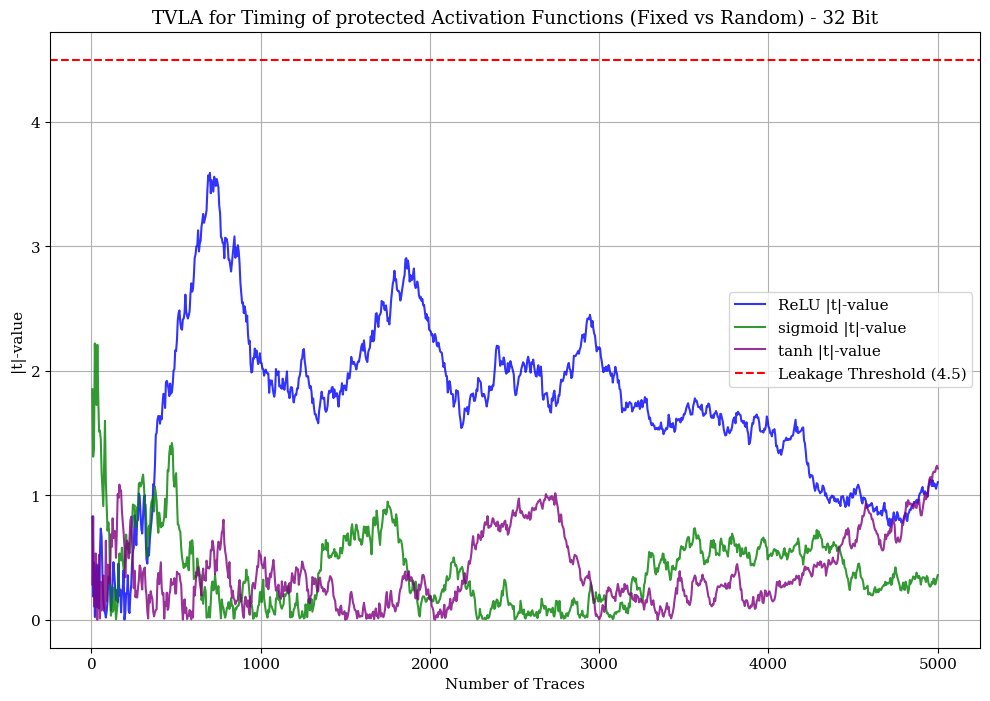

In [51]:
"""
TVLA TEST
"""

def calc_tvla_evolution(fixed_times, random_times):
    t_values = []
    traces_axis = range(5, len(fixed_times) + 1, 5)
    for i in traces_axis:
        t_stat, _ = ttest_ind(fixed_times[:i], random_times[:i], equal_var=False)
        t_values.append(abs(t_stat))
    return traces_axis, t_values

traces_axis, relu_t = calc_tvla_evolution(relu_fixed, relu_random)
_, sig_t = calc_tvla_evolution(sig_fixed, sig_random)
_, tanh_t = calc_tvla_evolution(tanh_fixed, tanh_random)


# Evolution of |t|-value overlayed
plt.figure(figsize=(12, 8))

plt.plot(traces_axis, relu_t, color='blue', label='ReLU |t|-value', alpha=0.8)
plt.plot(traces_axis, sig_t, color='green', label='sigmoid |t|-value', alpha=0.8)
plt.plot(traces_axis, tanh_t, color='purple', label='tanh |t|-value', alpha=0.8)

# Add the classical ±4.5 threshold line (since it's absolute |t|, just 4.5)
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Timing of protected Activation Functions (Fixed vs Random) - 32 Bit")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig(f"TVLA for Timing of protected Activation Functions (Fixed vs Random)_ARM.pdf", bbox_inches='tight')
plt.show()


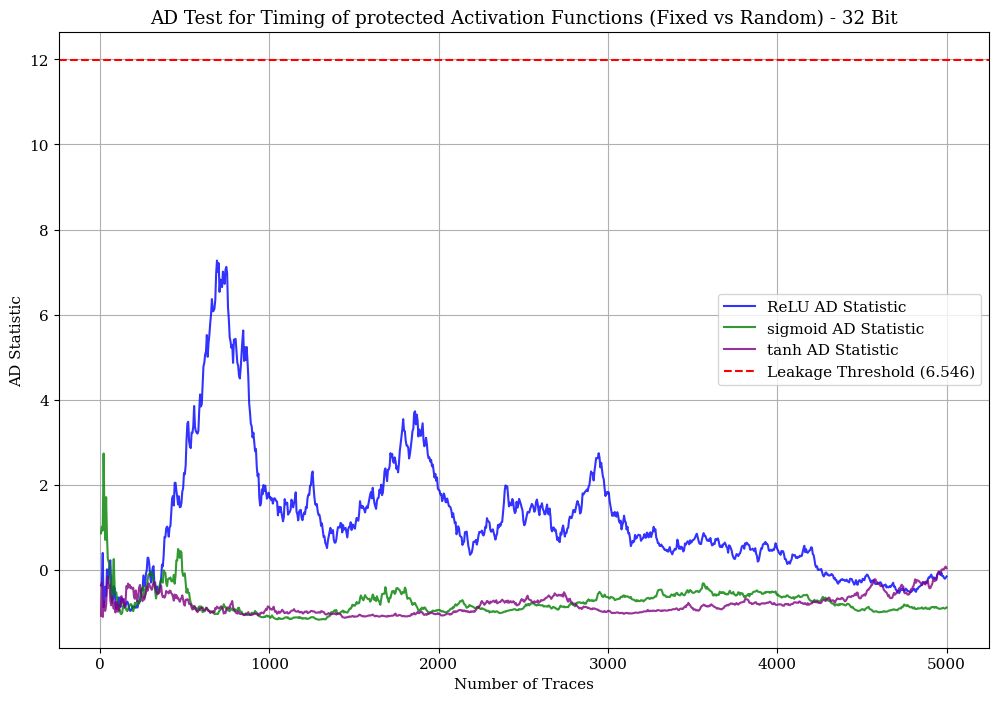

In [52]:
"""
AD TEST
"""

import struct
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.stats import anderson_ksamp
from tqdm.notebook import tqdm


def calc_ad_evolution(fixed_times, random_times):
    ad_values = []
    traces_axis = range(5, len(fixed_times) + 1, 5)
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i in traces_axis:
            res = anderson_ksamp([fixed_times[:i], random_times[:i]])
            ad_values.append(res.statistic) 
            
    return traces_axis, ad_values

traces_axis, relu_ad = calc_ad_evolution(relu_fixed, relu_random)
_, sig_ad = calc_ad_evolution(sig_fixed, sig_random)
_, tanh_ad = calc_ad_evolution(tanh_fixed, tanh_random)


# Evolution of AD-statistic overlayed
plt.figure(figsize=(12, 8))

plt.plot(traces_axis, relu_ad, color='blue', label='ReLU AD Statistic', alpha=0.8)
plt.plot(traces_axis, sig_ad, color='green', label='sigmoid AD Statistic', alpha=0.8)
plt.plot(traces_axis, tanh_ad, color='purple', label='tanh AD Statistic', alpha=0.8)


plt.axhline(11.99, color='red', linestyle='dashed', label='Leakage Threshold (6.546)')

plt.title("AD Test for Timing of protected Activation Functions (Fixed vs Random) - 32 Bit")
plt.xlabel("Number of Traces")
plt.ylabel("AD Statistic")
plt.legend()
plt.grid(True)
plt.savefig("AD_Test_Timing_protected_Activation_Functions_Fixed_vs_Random_ARM.pdf", bbox_inches='tight')
plt.show()


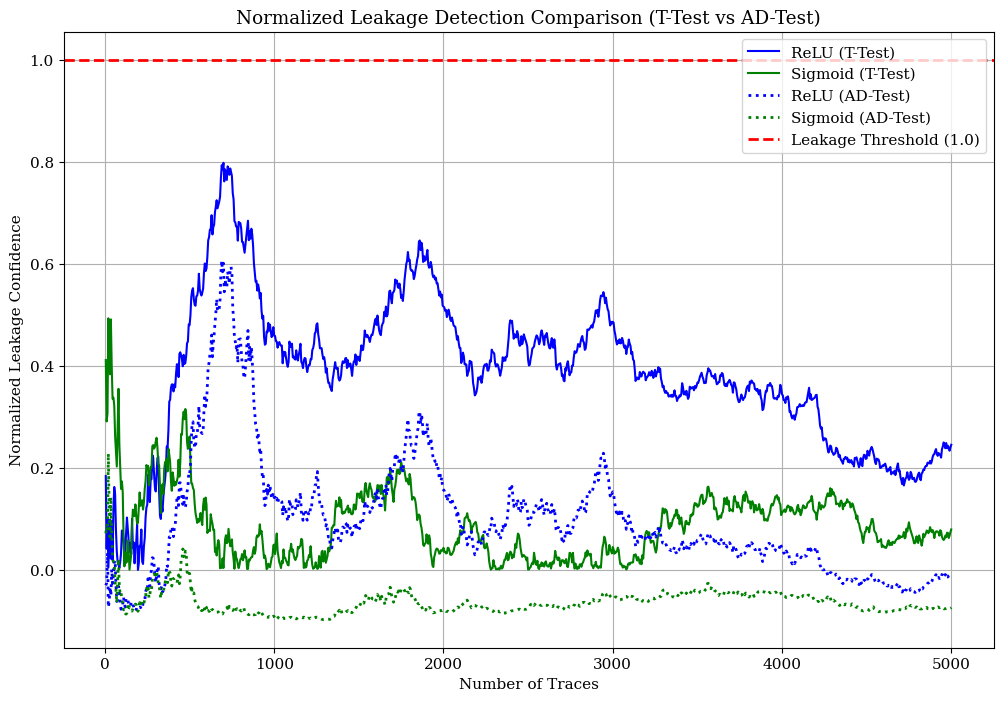

In [53]:
"""
Normalized plot
"""
import numpy as np

# --- 1. Normalize TVLA (t-test) values ---
# Divide by the standard TVLA threshold of 4.5
norm_relu_t = np.array(relu_t) / 4.5
norm_sig_t  = np.array(sig_t) / 4.5
norm_tanh_t = np.array(tanh_t) / 4.5

# --- 2. Normalize AD values ---
# Divide by the AD threshold of 11.99
norm_relu_ad = np.array(relu_ad) / 11.99
norm_sig_ad  = np.array(sig_ad) / 11.99
norm_tanh_ad = np.array(tanh_ad) / 11.99

plt.figure(figsize=(12, 8))

# Plot Normalized T-Tests (Solid Lines)
plt.plot(traces_axis, norm_relu_t, color='blue', linestyle='-', label='ReLU (T-Test)')
plt.plot(traces_axis, norm_sig_t, color='green', linestyle='-', label='Sigmoid (T-Test)')

# Plot Normalized AD-Tests (Dotted Lines)
plt.plot(traces_axis, norm_relu_ad, color='blue', linestyle=':', linewidth=2, label='ReLU (AD-Test)')
plt.plot(traces_axis, norm_sig_ad, color='green', linestyle=':', linewidth=2, label='Sigmoid (AD-Test)')

# Add the UNIVERSAL Normalized Threshold Line at exactly 1.0
plt.axhline(1.0, color='red', linestyle='dashed', linewidth=2, label='Leakage Threshold (1.0)')

plt.title("Normalized Leakage Detection Comparison (T-Test vs AD-Test)")
plt.xlabel("Number of Traces")
plt.ylabel("Normalized Leakage Confidence")
plt.legend()
plt.grid(True)
plt.show()



In [5]:
import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm

N = 5000

# Generate ONE set of random inputs to use for all three functions
shared_random_inputs = np.random.uniform(-2, 2, N)

def collect_traces(activation_name, choice_val):
    times = []
    print(f"Collecting {N} traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} Traces"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', shared_random_inputs[i]))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)
        
    return times

# Collect data for all three functions using the SAME input data array
relu_times = collect_traces("ReLU", 0)
sig_times = collect_traces("sigmoid", 1)
tanh_times = collect_traces("tanh", 2)

print("Calculating cross function TVLA evolution...")

# Calculate the evolving t-statistics over the number of traces
traces_axis = range(10, N + 1, 10) 

t_relu_vs_sig = []
t_sig_vs_tanh = []
t_relu_vs_tanh = []

for i in traces_axis:
    # 1. Compare ReLU vs Sigmoid
    t_stat1, _ = ttest_ind(relu_times[:i], sig_times[:i], equal_var=False)
    t_relu_vs_sig.append(abs(t_stat1))
    
    # 2. Compare Sigmoid vs Tanh
    t_stat2, _ = ttest_ind(sig_times[:i], tanh_times[:i], equal_var=False)
    t_sig_vs_tanh.append(abs(t_stat2))
    
    # 3. Compare ReLU vs Tanh
    t_stat3, _ = ttest_ind(relu_times[:i], tanh_times[:i], equal_var=False)
    t_relu_vs_tanh.append(abs(t_stat3))


ReLU Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating cross function TVLA evolution...


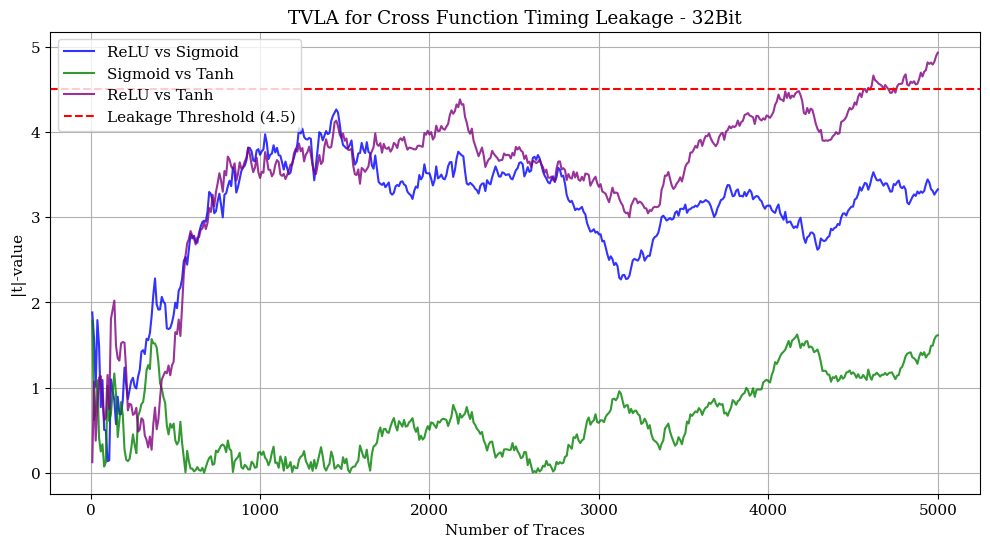

In [6]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})
# Plotting the Inter-Function Leakage
plt.figure(figsize=(12, 6))

plt.plot(traces_axis, t_relu_vs_sig, color='blue', label='ReLU vs Sigmoid', alpha=0.8)
plt.plot(traces_axis, t_sig_vs_tanh, color='green', label='Sigmoid vs Tanh', alpha=0.8)
plt.plot(traces_axis, t_relu_vs_tanh, color='purple', label='ReLU vs Tanh', alpha=0.8)

# Threshold line
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Cross Function Timing Leakage - 32Bit")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig('TVLA for Cross Function Timing Leakage_ARM.pdf', bbox_inches='tight')
plt.show()


Calculating cross function AD-test evolution...


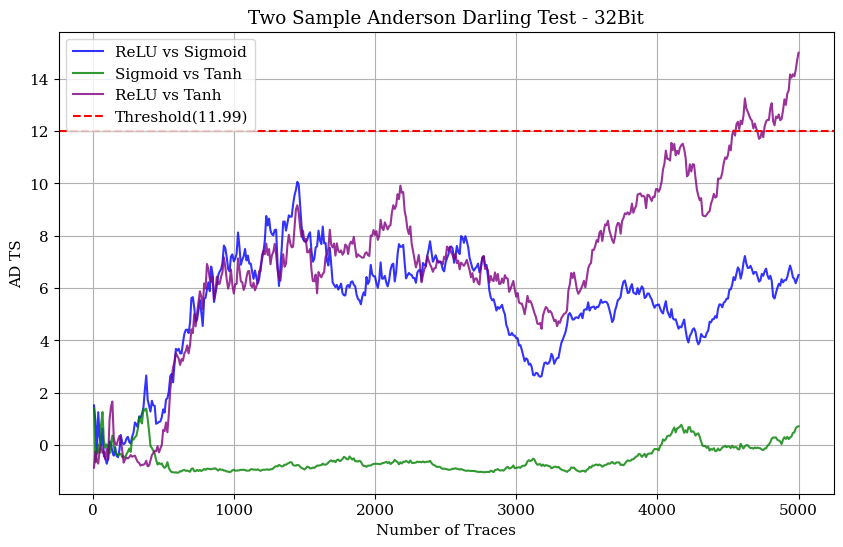

In [7]:
import warnings
from scipy.stats import anderson_ksamp
import matplotlib.pyplot as plt


print("Calculating cross function AD-test evolution...")

ad_relu_vs_sig = []
ad_sig_vs_tanh = []
ad_relu_vs_tanh = []

# The anderson_ksamp function often throws warnings when the estimated p-value
# is extremely small (< 0.001) or very large (> 0.25). 
# We suppress these warnings here to prevent flooding your output during the loop.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for i in traces_axis:
        # anderson_ksamp takes a list of the sample arrays you want to compare.
        # It returns an object containing the 'statistic', 'critical_values', and 'pvalue'.
        # We extract .statistic as our leakage metric.
        
        # 1. Compare ReLU vs Sigmoid
        res1 = anderson_ksamp([relu_times[:i], sig_times[:i]])
        ad_relu_vs_sig.append(res1.statistic)
        
        # 2. Compare Sigmoid vs Tanh
        res2 = anderson_ksamp([sig_times[:i], tanh_times[:i]])
        ad_sig_vs_tanh.append(res2.statistic)
        
        # 3. Compare ReLU vs Tanh
        res3 = anderson_ksamp([relu_times[:i], tanh_times[:i]])
        ad_relu_vs_tanh.append(res3.statistic)

# --- Plotting the Results ---
plt.figure(figsize=(10, 6))

plt.plot(traces_axis, ad_relu_vs_sig, color="blue", label='ReLU vs Sigmoid', alpha=0.8)
plt.plot(traces_axis, ad_sig_vs_tanh, color="green", label='Sigmoid vs Tanh', alpha=0.8)
plt.plot(traces_axis, ad_relu_vs_tanh, color="purple", label='ReLU vs Tanh', alpha=0.8)

# For a 2-sample AD-test, the critical value for a 0.001 (0.1%) significance level 
# is typically ~6.546 based on Scipy's tabulated values.
# If a statistic goes over this line, we confidently reject the null hypothesis 
# that the distributions are identical (indicating a timing leakage).
plt.axhline(y=11.99, color='red', linestyle='--', label='Threshold(11.99)')

plt.title('Two Sample Anderson Darling Test - 32Bit')
plt.xlabel('Number of Traces')
plt.ylabel('AD TS')
plt.legend()
plt.grid(True)
plt.savefig('Two Sample Anderson Darling Test_ARM.pdf', bbox_inches='tight')
plt.show()
